# Credit Card Fraud Detection — Cross-validation and Random Forest tuning

This revision audits duplicate records, reserves a stratified 20% test set, and tunes a Random Forest using **RandomizedSearchCV**, **Stratified 5-Fold CV**, and **average precision (AP)**. The final model is selected on training CV scores only.

Place `creditcard.csv` beside this notebook and open that folder in VS Code. Run cells from top to bottom. If needed, run the optional installation cell, then restart the kernel.

The previous fixed-model comparison (including SMOTE) is replaced by a focused Random Forest search. No resampling or scaling is needed for this workflow. Historical outputs have been cleared; run this notebook to obtain actual results.

Dataset: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud

In [1]:
# Optional: uncomment and run once in a NOTEBOOK cell (not PowerShell).
# %pip install numpy pandas matplotlib seaborn scikit-learn joblib

## 1. Imports and reproducible configuration

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import joblib
from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score, accuracy_score,
    average_precision_score, roc_auc_score, PrecisionRecallDisplay, RocCurveDisplay)

RANDOM_STATE = 42
N_ITER = 20  # 20 sampled configurations x 5 folds = 100 fits, plus final refit.
SEARCH_JOBS = 2  # Set to 1 if your laptop has limited RAM.
THRESHOLD = 0.5  # Fixed before looking at test results; do not tune on the test set.
BASE_DIR = Path.cwd()
DATA_PATH = BASE_DIR / 'creditcard.csv'
OUTPUT_DIR = BASE_DIR / 'outputs_cv'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
if not DATA_PATH.exists():
    raise FileNotFoundError(f'Place creditcard.csv here: {DATA_PATH}')

## 2. Validate and investigate duplicate transactions

We audit exact duplicates across **all columns**, including the label. The dataset has no reliable unique transaction ID, so identical rows cannot be proven to be erroneous copies. For this educational experiment, we retain one copy of each exact record to prevent identical observations leaking across training, CV, and test sets. This changes the population and may change fraud prevalence; the audit records the impact.

We also check identical feature vectors with conflicting labels. If found, execution stops for investigation rather than arbitrarily assigning a label. No learned preprocessing is fitted during this structural audit.

In [2]:
df = pd.read_csv(DATA_PATH)
expected = {'Time', 'Amount', 'Class'} | {f'V{i}' for i in range(1, 29)}
if set(df.columns) != expected:
    raise ValueError('Expected Time, V1–V28, Amount, and Class columns.')
if df.isna().any().any():
    raise ValueError('Missing values found. Investigate before modeling.')
if not all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes):
    raise ValueError('All dataset columns must be numeric.')
if not np.isfinite(df.to_numpy()).all():
    raise ValueError('Infinite values found.')
if set(df['Class'].unique()) != {0, 1}:
    raise ValueError('Class must contain both 0 (legitimate) and 1 (fraud).')

feature_columns = df.columns.drop('Class').tolist()
duplicate_mask = df.duplicated(keep='first')
audit = pd.DataFrame({
    'original_count': df['Class'].value_counts(),
    'removed_exact_duplicates': df.loc[duplicate_mask, 'Class'].value_counts()
}).fillna(0).astype(int).sort_index()
audit['retained_count'] = audit['original_count'] - audit['removed_exact_duplicates']
audit.index.name = 'Class'
print('Original shape:', df.shape)
print('Exact duplicate rows removed:', int(duplicate_mask.sum()))
display(audit)
audit.to_csv(OUTPUT_DIR / 'duplicate_audit.csv')

clean_df = df.drop_duplicates().copy()
# After full-row deduplication, repeated features imply conflicting labels.
conflict_mask = clean_df.duplicated(subset=feature_columns, keep=False)
if conflict_mask.any():
    display(clean_df.loc[conflict_mask].head(10))
    raise ValueError('Identical features have conflicting labels. Investigate before splitting.')
print('Retained shape:', clean_df.shape)
print('Fraud proportion before:', df['Class'].mean())
print('Fraud proportion after:', clean_df['Class'].mean())

Original shape: (284807, 31)
Exact duplicate rows removed: 1081


,original_count,removed_exact_duplicates,retained_count
Class,,,
0,284315,1062,283253
1,492,19,473


Retained shape: (283726, 31)
Fraud proportion before: 0.001727485630620034
Fraud proportion after: 0.001667101358352777


## 3. Reserve the test set before model development

Use 80% for training and CV; reserve 20% for final evaluation. Original row indices are saved for reproducibility. Exact feature matches are checked directly across the split. Do not inspect test performance until all modeling decisions are fixed.

In [3]:
X = clean_df[feature_columns]
y = clean_df['Class'].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, train_size=0.25, stratify=y, random_state=RANDOM_STATE)
assert set(X_train.index).isdisjoint(X_test.index)
assert not pd.MultiIndex.from_frame(X_train).isin(pd.MultiIndex.from_frame(X_test)).any()
if y_train.value_counts().min() < 5:
    raise ValueError('Each class needs at least five training examples for 5-fold CV.')
pd.DataFrame({'original_row_index': X_train.index}).to_csv(OUTPUT_DIR / 'train_indices.csv', index=False)
pd.DataFrame({'original_row_index': X_test.index}).to_csv(OUTPUT_DIR / 'test_indices.csv', index=False)
print('Training rows:', len(X_train), '| Reserved test rows:', len(X_test))
print('Training class counts:')
print(y_train.value_counts().sort_index())

Training rows: 70931 | Reserved test rows: 212795
Training class counts:
Class
0    70813
1      118
Name: count, dtype: int64


## 4. Exploratory analysis — training data only

In [4]:
eda_df = X_train.assign(Class=y_train)
display(eda_df[['Time', 'Amount', 'Class']].describe())

,Time,Amount,Class
count,70931.000000,70931.000000,70931.000000
mean,94932.388688,87.651828,0.001664
std,47494.791230,242.154487,0.040753
min,2.000000,0.000000,0.000000
25%,54275.500000,5.500000,0.000000
50%,84929.000000,21.980000,0.000000
75%,139430.500000,76.840000,0.000000
max,172788.000000,18910.000000,1.000000


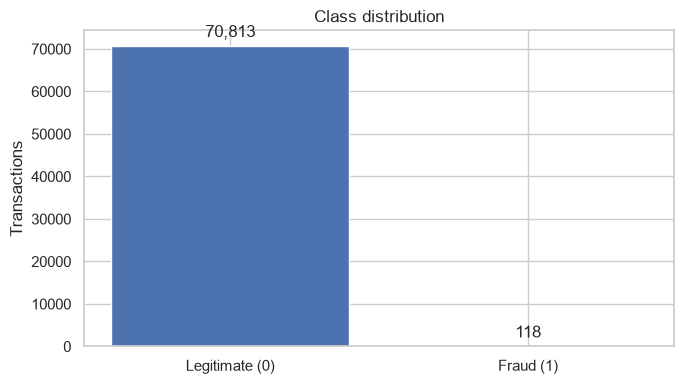

In [5]:
class_counts = eda_df['Class'].value_counts().sort_index()
fig,ax=plt.subplots(figsize=(7,4))
ax.bar(['Legitimate (0)','Fraud (1)'], class_counts.values)
ax.set(title='Class distribution', ylabel='Transactions')
for i,v in enumerate(class_counts.values): ax.text(i,v+2000,f'{v:,}',ha='center')
fig.tight_layout(); fig.savefig(OUTPUT_DIR/'01_class_distribution.png',dpi=150);plt.show()

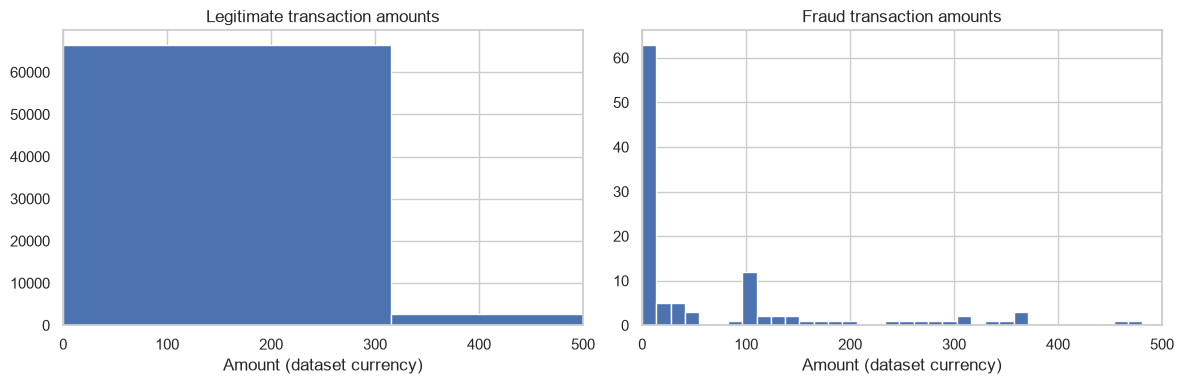

In [6]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,c in zip(axes,[0,1]):
    ax.hist(eda_df.loc[eda_df.Class==c,'Amount'],bins=60)
    ax.set(title=('Legitimate' if c==0 else 'Fraud')+' transaction amounts',xlabel='Amount (dataset currency)')
    ax.set_xlim(0,500)
fig.tight_layout();fig.savefig(OUTPUT_DIR/'02_amount_distribution.png',dpi=150);plt.show()

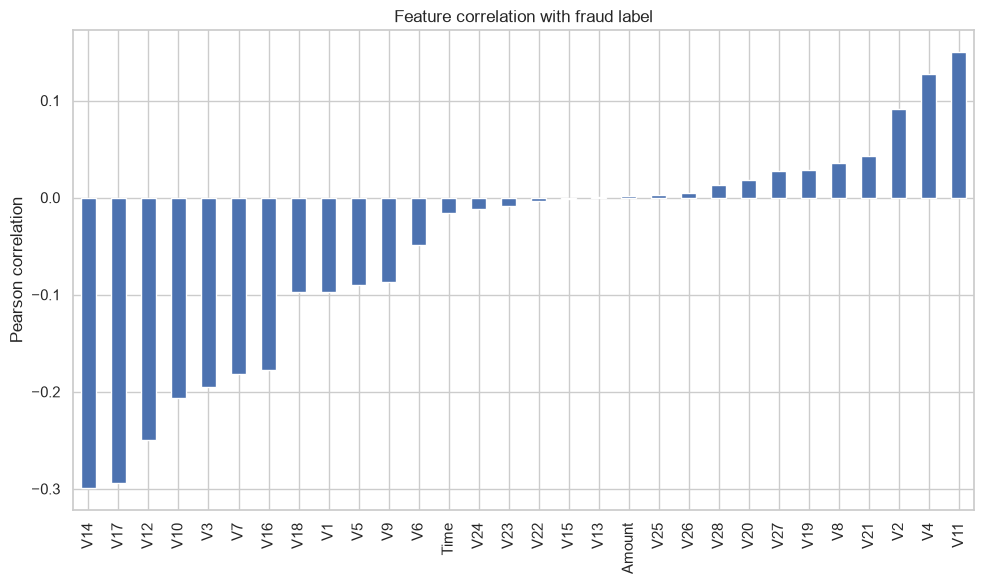

In [7]:
corr=eda_df.corr(numeric_only=True)['Class'].drop('Class').sort_values()
fig,ax=plt.subplots(figsize=(10,6))
corr.plot(kind='bar',ax=ax)
ax.set(title='Feature correlation with fraud label',ylabel='Pearson correlation')
fig.tight_layout();fig.savefig(OUTPUT_DIR/'03_feature_correlations.png',dpi=150);plt.show()

## 5. Stratified 5-fold cross-validation and hyperparameter search

Each fold trains on four parts of the training data and validates on the fifth. Stratification approximately preserves the rare fraud proportion. All configurations use the same folds.

The search samples 20 configurations and ranks them by mean validation **average precision** (`scoring='average_precision'`). AP summarizes the precision–recall relationship across thresholds; it is not the precision at threshold 0.5 or trapezoidal PR-AUC. Higher is better.

We search tree count, depth, split/leaf sizes, feature sampling, and class weights. `refit=True` automatically retrains the winning configuration on all training rows. Search parallelism is limited to two workers, with one worker per forest to avoid nested CPU overload. Full-data training can take substantial time.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
param_distributions = {
    "n_estimators": [50, 100],
    "max_depth": [10, 20],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt"]
}
search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=1),
    param_distributions=param_distributions,
    n_iter=N_ITER,
    scoring='average_precision',
    cv=cv,
    refit=True,
    random_state=RANDOM_STATE,
    n_jobs=SEARCH_JOBS,
    pre_dispatch=SEARCH_JOBS,
    return_train_score=False,
    error_score='raise',
    verbose=2
)
# Only training data enters the search; X_test and y_test are never passed here.
search.fit(X_train, y_train)
best_model = search.best_estimator_
print('Best hyperparameters:', search.best_params_)
print(f'Best mean CV average precision: {search.best_score_:.4f}')

e:\py\VS CODE FILES\Credit_Card_Fraud_Detection_with_Imbalanced_Data\.venv\Lib\site-packages\sklearn\model_selection\_search.py:327: UserWarning: The total space of parameters 16 is smaller than n_iter=20. Running 16 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Fitting 5 folds for each of 16 candidates, totalling 80 fits
Best hyperparameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 10}
Best mean CV average precision: 0.7972


## 6. Inspect and save training CV results

The winning CV score is used for selection and may be optimistic after searching many configurations. It is not the final held-out test score. The fold standard deviation describes variation across five folds, not a confidence interval.

In [9]:
cv_results = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
cv_results.to_csv(OUTPUT_DIR / 'randomized_search_cv_results.csv', index=False)
display(cv_results[['rank_test_score', 'mean_test_score', 'std_test_score', 'params']].head(10))
best_index = search.best_index_
fold_scores = [float(search.cv_results_[f'split{i}_test_score'][best_index]) for i in range(5)]
display(pd.DataFrame({'Fold': range(1, 6), 'Validation AP': fold_scores}))
print(f'Winning CV AP: {np.mean(fold_scores):.4f} ± {np.std(fold_scores):.4f}')

,rank_test_score,mean_test_score,std_test_score,params
1,1,0.797182,0.100670,"{'n_estimators': 100, 'min_samples_split': 2, ..."
11,2,0.795115,0.103723,"{'n_estimators': 100, 'min_samples_split': 5, ..."
13,3,0.794701,0.103915,"{'n_estimators': 100, 'min_samples_split': 2, ..."
3,4,0.793711,0.102324,"{'n_estimators': 100, 'min_samples_split': 5, ..."
9,5,0.792145,0.101374,"{'n_estimators': 100, 'min_samples_split': 2, ..."
6,6,0.790946,0.100248,"{'n_estimators': 50, 'min_samples_split': 5, '..."
12,7,0.790567,0.098580,"{'n_estimators': 50, 'min_samples_split': 2, '..."
14,8,0.790474,0.101568,"{'n_estimators': 50, 'min_samples_split': 5, '..."
5,9,0.790414,0.103523,"{'n_estimators': 100, 'min_samples_split': 2, ..."
2,10,0.790327,0.100605,"{'n_estimators': 50, 'min_samples_split': 5, '..."


,Fold,Validation AP
0,1,0.698613
1,2,0.742275
2,3,0.926411
3,4,0.911648
4,5,0.706965


Winning CV AP: 0.7972 ± 0.1007


## 7. Final evaluation on the reserved test set

The configuration and threshold (0.5) are now fixed. Evaluate this selected model once. Do not use these results to change parameters or the threshold. If threshold tuning is needed in a future experiment, use training-only out-of-fold predictions or a separate validation set.

**Historical holdout limitation:** if this dataset or test rows were already used for decisions in earlier notebook runs, this split is not a genuinely unseen external test. The revised code prevents further selection on test results; a fresh external or temporal holdout would provide stronger evidence.

,Accuracy,Precision,Recall,F1,Average Precision,ROC-AUC
Tuned Random Forest,0.9995,0.9315,0.7662,0.8408,0.8266,0.968


              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00    212440
       Fraud       0.93      0.77      0.84       355

    accuracy                           1.00    212795
   macro avg       0.97      0.88      0.92    212795
weighted avg       1.00      1.00      1.00    212795



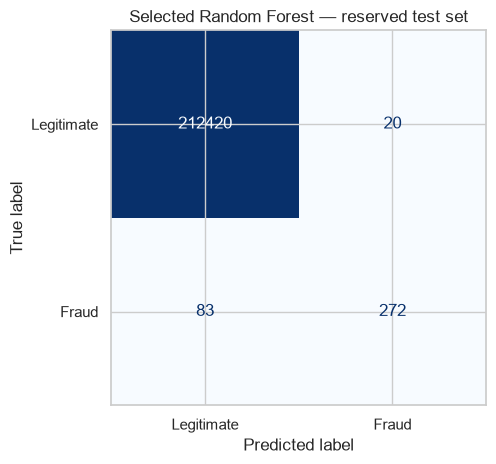

In [14]:
test_probabilities = best_model.predict_proba(X_test)[:, list(best_model.classes_).index(1)]
test_predictions = (test_probabilities >= THRESHOLD).astype(int)
metrics = {
    'Accuracy': accuracy_score(y_test, test_predictions),
    'Precision': precision_score(y_test, test_predictions, zero_division=0),
    'Recall': recall_score(y_test, test_predictions, zero_division=0),
    'F1': f1_score(y_test, test_predictions, zero_division=0),
    'Average Precision': average_precision_score(y_test, test_probabilities),
    'ROC-AUC': roc_auc_score(y_test, test_probabilities)
}
results = pd.DataFrame([metrics], index=['Tuned Random Forest'])
display(results.round(4))
results.to_csv(OUTPUT_DIR / 'final_test_metrics.csv', index_label='Model')
print(classification_report(y_test, test_predictions, labels=[0, 1],
    target_names=['Legitimate', 'Fraud'], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, test_predictions, labels=[0, 1],
    display_labels=['Legitimate', 'Fraud'], cmap='Blues', colorbar=False)
plt.title('Selected Random Forest — reserved test set')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '04_confusion_matrix.png', dpi=150)
plt.show()

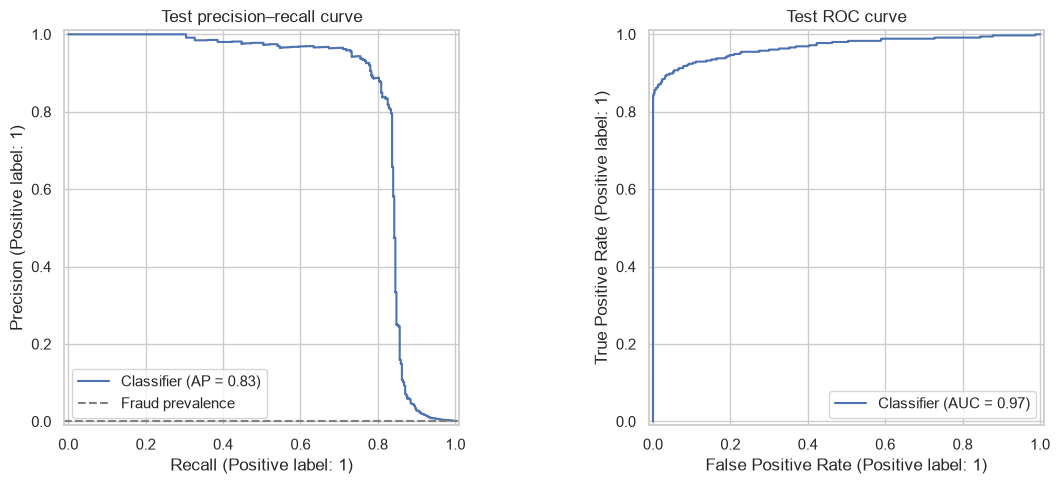

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
PrecisionRecallDisplay.from_predictions(y_test, test_probabilities, ax=axes[0])
axes[0].axhline(y_test.mean(), color='gray', linestyle='--', label='Fraud prevalence')
axes[0].legend()
axes[0].set_title('Test precision–recall curve')
RocCurveDisplay.from_predictions(y_test, test_probabilities, ax=axes[1])
axes[1].set_title('Test ROC curve')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / '05_test_curves.png', dpi=150)
plt.show()

## 8. Feature importance and model export

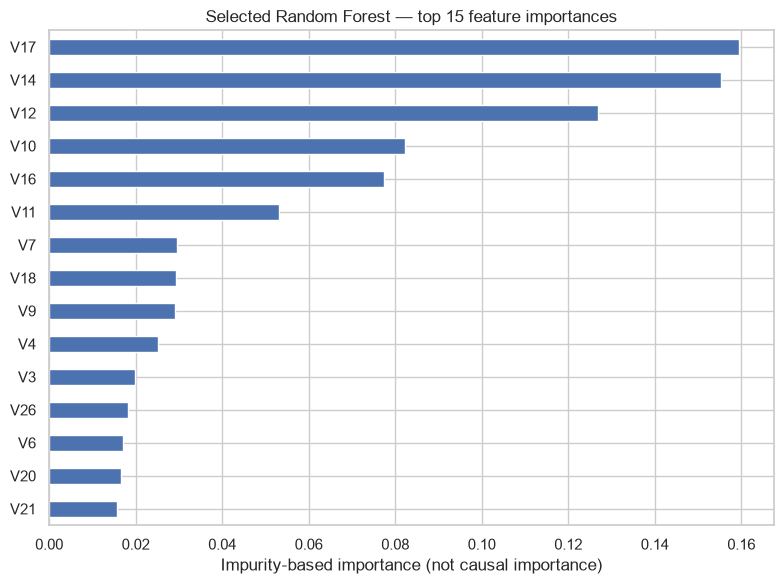

Saved model, audit, split indices, CV results, plots, and final metrics in: e:\py\VS CODE FILES\Credit_Card_Fraud_Detection_with_Imbalanced_Data\outputs_cv


In [15]:
importance = pd.Series(best_model.feature_importances_, index=feature_columns).sort_values()
importance.tail(15).plot.barh(figsize=(8, 6))
plt.title('Selected Random Forest — top 15 feature importances')
plt.xlabel('Impurity-based importance (not causal importance)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '06_feature_importance.png', dpi=150)
plt.show()
importance.to_csv(OUTPUT_DIR / 'feature_importance.csv', header=['importance'])
joblib.dump(best_model, OUTPUT_DIR / 'fraud_detection_model.joblib')
metadata = {
    'random_state': RANDOM_STATE, 'cv_folds': 5, 'search_iterations': N_ITER,
    'selection_metric': 'average_precision', 'best_parameters': search.best_params_,
    'best_cv_average_precision': float(search.best_score_),
    'best_cv_fold_scores': fold_scores, 'threshold': THRESHOLD,
    'training_rows': len(X_train), 'test_rows': len(X_test),
    'removed_exact_duplicates': int(duplicate_mask.sum()),
    'duplicate_policy': 'Keep first exact row; stop on conflicting feature labels.',
    'feature_columns': feature_columns, 'test_metrics': metrics,
    'python_version': platform.python_version(), 'sklearn_version': sklearn.__version__,
    'pandas_version': pd.__version__, 'numpy_version': np.__version__
}
with open(OUTPUT_DIR / 'experiment_summary.json', 'w', encoding='utf-8') as f:
    json.dump(metadata, f, indent=2)
print('Saved model, audit, split indices, CV results, plots, and final metrics in:', OUTPUT_DIR)

## Interpretation and reporting

- Use the actual values in `experiment_summary.json` and `final_test_metrics.csv` in your resume. Do not claim results before running the full search.
- Report the dataset size **after** deduplication, search size, 5-fold CV AP, and final test AP/precision/recall. Accuracy alone is misleading for rare fraud.
- The 0.5 threshold is a fixed baseline; changing it changes precision and recall.
- This random split measures performance within this historical dataset. It does not measure future performance under temporal drift. A temporal evaluation is a useful separate experiment.
- Exact-match deduplication cannot detect all near-duplicate or customer-related leakage; anonymized features limit investigation.
- Keep the large CSV and generated model out of GitHub. Share dataset download instructions and the notebook. Only load trusted `.joblib` files.